# 02 — Exploratory Data Analysis (EDA)

EDA membantu kita memahami distribusi, pola, dan kualitas data sebelum membuat model machine learning.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = PROJECT_DIR / 'data'
games = pd.read_csv(DATA_DIR / 'games_eda.csv')
reviews = pd.read_csv(DATA_DIR / 'player_reviews.csv')
games.head()

,game_id,title,genre,platform,release_year,studio,rating,price_usd,sales_millions,review_count
0,1,Wild Voyage 01,Strategy,PlayStation,2017,Northstar Studio,6.1,14.99,1.05,1357
1,2,Amber Islands 02,Strategy,Switch,2025,Blue Comet,6.4,14.99,2.51,15922
2,3,Amber Frontier 03,Puzzle,Xbox,2019,Orbit Works,9.1,4.99,6.27,10055
3,4,Cosmic Legends 04,Adventure,Xbox,2016,Maple Byte,8.3,61.99,2.10,3181
4,5,Frost Racers 05,Strategy,Xbox,2020,Orbit Works,5.9,9.99,3.10,6481


## 1. Pemeriksaan kualitas data

In [2]:
print('Ukuran data:', games.shape)
print('\nTipe data:')
print(games.dtypes)
print('\nNilai kosong:')
print(games.isna().sum())
print('\nBaris duplikat:', games.duplicated().sum())

Ukuran data: (80, 10)

Tipe data:
game_id             int64
title                 str
genre                 str
platform              str
release_year        int64
studio                str
rating            float64
price_usd         float64
sales_millions    float64
review_count        int64
dtype: object

Nilai kosong:
game_id           0
title             0
genre             0
platform          0
release_year      0
studio            0
rating            0
price_usd         0
sales_millions    0
review_count      0
dtype: int64

Baris duplikat: 0


## 2. Statistik deskriptif

In [3]:
display(games[['release_year','rating','price_usd','sales_millions','review_count']].describe().round(2))

,release_year,rating,price_usd,sales_millions,review_count
count,80.00,80.00,80.00,80.00,80.00
mean,2019.78,7.08,26.90,4.55,8414.01
std,3.10,1.28,21.39,4.18,5577.39
min,2014.00,3.80,0.00,0.45,53.00
25%,2017.00,6.30,9.99,2.15,3200.50
50%,2020.00,6.80,18.49,3.26,8355.50
75%,2022.00,7.95,49.99,5.66,13775.50
max,2025.00,10.00,61.99,26.98,17998.00


## 3. Jumlah game per genre

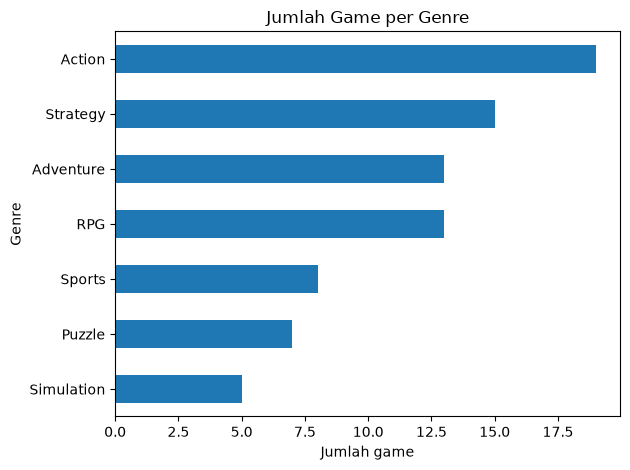

In [4]:
genre_counts = games['genre'].value_counts().sort_values()
genre_counts.plot(kind='barh')
plt.title('Jumlah Game per Genre')
plt.xlabel('Jumlah game')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

## 4. Rating dan penjualan

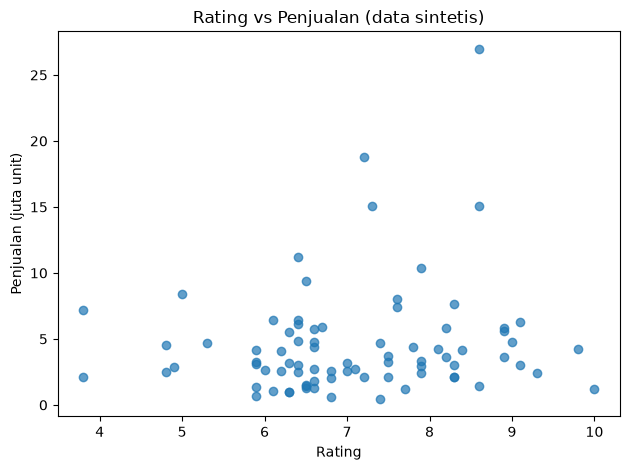

In [5]:
plt.scatter(games['rating'], games['sales_millions'], alpha=0.7)
plt.title('Rating vs Penjualan (data sintetis)')
plt.xlabel('Rating')
plt.ylabel('Penjualan (juta unit)')
plt.tight_layout()
plt.show()

## 5. Perbandingan rating rata-rata per platform

,platform,rating
4,Xbox,7.30
0,Mobile,7.15
1,PC,7.11
2,PlayStation,7.03
3,Switch,6.79


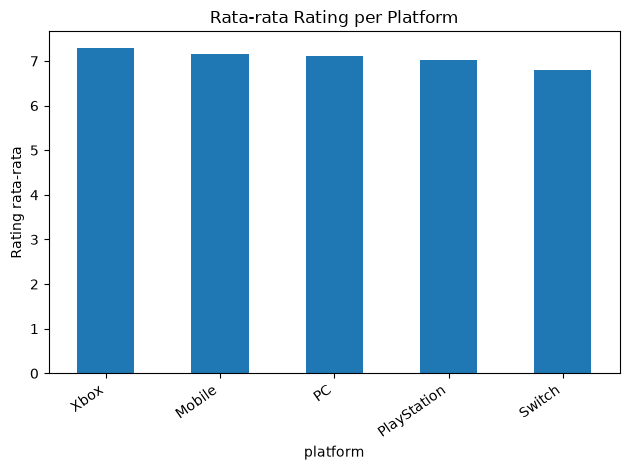

In [6]:
platform_rating = games.groupby('platform', as_index=False)['rating'].mean().sort_values('rating', ascending=False)
display(platform_rating.round(2))
platform_rating.plot(x='platform', y='rating', kind='bar', legend=False)
plt.title('Rata-rata Rating per Platform')
plt.ylabel('Rating rata-rata')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## 6. Gabungkan ulasan dan game

In [7]:
review_summary = reviews.groupby('game_id', as_index=False).agg(
    avg_review_score=('review_score','mean'),
    avg_play_hours=('play_hours','mean'),
    total_reviews=('review_id','count')
)
eda_data = games.merge(review_summary, on='game_id', how='left')
display(eda_data[['title','genre','rating','avg_review_score','avg_play_hours','total_reviews']].head(10).round(2))

,title,genre,rating,avg_review_score,avg_play_hours,total_reviews
0,Wild Voyage 01,Strategy,6.1,NaN,NaN,NaN
1,Amber Islands 02,Strategy,6.4,6.50,10.67,6.0
2,Amber Frontier 03,Puzzle,9.1,9.25,15.29,8.0
3,Cosmic Legends 04,Adventure,8.3,9.00,11.35,2.0
4,Frost Racers 05,Strategy,5.9,NaN,NaN,NaN
5,Crystal Voyage 06,Action,5.9,7.00,15.17,3.0
6,Forgotten Realm 07,Sports,4.8,NaN,NaN,NaN
7,Solar Labyrinth 08,RPG,6.5,7.00,5.35,2.0
8,Golden Labyrinth 09,Adventure,7.4,9.00,3.10,2.0
9,Frost Academy 10,Strategy,8.6,9.00,29.17,3.0


## Kesimpulan yang perlu ditulis
Jawab dengan kalimatmu sendiri:
1. Genre apa yang paling banyak muncul?
2. Apakah rating dan penjualan tampak berhubungan? (Hubungan pada grafik tidak membuktikan sebab-akibat.)
3. Platform mana yang memiliki rata-rata rating tertinggi?
4. Apakah ada nilai kosong atau duplikat yang perlu ditangani?